# Compare cell types across multiome datasets

Start with a row per dataset, sample or library, and harmonized cell type. Compare the same cell type across datasets where it exists. Use the per-cell tables to see whether a group difference reflects a shift across cells or a few outliers.

The QC section uses the RNA and ATAC count layers and pairs cells by observation name. Set the file paths below or run the cells in a notebook where `mdata` already exists. Run datasets separately if they use different peak sets. Within a file, the matrix dimensions describe the shared feature universe. Outer-joined matrices require an assay-specific feature mask to distinguish structural missingness from zero counts.

Use a biological sample or donor column for replication if available. The example groups by `library` because it is present in the supplied object. Set `SAMPLE_COL = None` to pool each dataset and cell type. Harmonize cell-type labels upstream and check unlabeled cells before comparing groups.

## Load Processed Dataset

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import muon as mu
import json
import mudata

mudata.set_options(pull_on_update=False)

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
PROJECT_DATA_DIR = Path("/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
RAW_DATA_DIR = PROJECT_DATA_DIR / "RAW_DATA" / "HUMAN"

SAMPLE_NAME = "colon_adult_ENCDO856ZOJ"
ORGANISM_CODE = "hg38"
TISSUE = "colon"
DATASET_NAME = "ENCODE_colon"

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed" / ORGANISM_CODE / DATASET_NAME
SAMPLE_PROCESSED_DATA_DIR = PROCESSED_DATA_DIR / SAMPLE_NAME

full_metadata_df = pd.read_csv(RAW_DATA_DIR / "metadata_summary.tsv", sep="\t", header=0)

sample_metadata_df = full_metadata_df[
    (full_metadata_df["dataset"] == DATASET_NAME) &
    (full_metadata_df["library"] == SAMPLE_NAME)
    ]

assert sample_metadata_df["status"].iloc[0] == "ready", f"Sample is not ready: {sample_metadata_df['status'].iloc[0]}"

information_cols = ["dataset", "library", "tissue", "age", "condition", "sex_reported", "status_note"]
for col in information_cols:
    print(f"{col}: {sample_metadata_df[col].iloc[0]}")

peaks_folder = RAW_DATA_DIR / sample_metadata_df["peaks_folder"].iloc[0]

peak_summary = peaks_folder / "peaks_summary.json"
h5mu_summary = peaks_folder / "h5mu_summary.json"

sample_raw_data_dir = RAW_DATA_DIR / sample_metadata_df["raw_folder"].iloc[0]
frag_path = RAW_DATA_DIR / sample_raw_data_dir / "fragments_atac_barcodes.tsv.gz"

with open(peak_summary) as f:
    peak_summary_dict = json.load(f)

with open(h5mu_summary) as f:
    h5mu_summary_dict = json.load(f)

mdata = mu.read_h5mu(SAMPLE_PROCESSED_DATA_DIR / "multiome_processed.h5mu")

rna = mdata["rna"]
atac = mdata["atac"]

display(mdata)

print("Peak summary:")
display(peak_summary_dict)

print("h5mu summary:")
display(h5mu_summary_dict)

dataset: ENCODE_colon
library: colon_adult_ENCDO856ZOJ
tissue: left colon
age: 59
condition: adult
sex_reported: female
status_note: MACS3 peaks and raw .h5mu built


MuData object with n_obs × n_vars = 7584 × 136471
  obs:	'dataset', 'library'
  var:	'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
  uns:	'source'
  2 modalities
    rna:	7584 x 25573
      obs:	'barcode_rna', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', 'doublet_score', 'predicted_doublet', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'leiden_res1_25', 'Epithelial (general)_score', 'Colonocyte (upper crypt)_score', 'Colonocyte (lower crypt)_score', 'BEST4+ colonocyte_score', 'Endothelial_score', 'Pericyte/smooth muscle_score', 'Fibroblast_score', 'T cell_score', 'NK cell_score', 'B cell_score', 'Plasma cell_score', 'Monocyte_score', 'Macrophage_score', 'Dendritic cell_score', 'Mast cell_score', 'Colonocyte_score', 'Goblet cell_score', 'Intestinal stem/TA cell_score', 'Enteroendocrine cell_score', 'Tuft cell_score', 'Smooth muscle_score', 'Enteric glia/neuron_score', 'Cycling cells_score', 'celltype'
      var:	'gene_id', 'gene_ids', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
      uns:	'celltype_colors', 'dendrogram_leiden_res1', 'hvg', 'leiden_res0_25', 'leiden_res0_25_colors', 'leiden_res0_5', 'leiden_res0_5_colors', 'leiden_res1', 'leiden_res1_25', 'leiden_res1_25_colors', 'leiden_res1_colors', 'log1p', 'neighbors', 'pca', 'scrublet', 'umap'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    atac:	7584 x 110898
      obs:	'n_genes_by_counts', 'total_counts', 'tss_score', 'outlier', 'NS', 'nucleosome_signal', 'n_counts', 'leiden'
      var:	'chrom', 'start', 'end', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'nearest_gene', 'TSS_dist', 'TSS_dist_score'
      uns:	'files', 'leiden', 'leiden_colors', 'log1p', 'lsi', 'neighbors', 'peak_gene_distance_params', 'peak_gene_links', 'umap'
      obsm:	'X_lsi', 'X_umap'
      varm:	'LSI'
      layers:	'counts'
      obsp:	'connectivities', 'distances'

Peak summary:


{'dataset': 'ENCODE_colon',
 'library': 'colon_adult_ENCDO856ZOJ',
 'cells': 12955,
 'cells_seen_first_10M_fragments': 12955,
 'fragments_counted_by_macs3': 184674233,
 'peaks_macs3': 115767,
 'peaks_on_chr1_22_X_Y': 115603,
 'peaks_final': 114463,
 'width_median': 630,
 'width_mean': 769,
 'width_max': 4599,
 'bp_total': 88040245,
 'method': 'macs3 3.0.4 callpeak -f FRAG --barcodes -g hs -q 0.01; chr1-22,X,Y; ENCODE hg38 blacklist v2 removed'}

h5mu summary:


{'dataset': 'ENCODE_colon',
 'library': 'colon_adult_ENCDO856ZOJ',
 'cells': 12955,
 'genes': 59526,
 'rna_integer_counts': True,
 'median_rna_umi': 3803.0,
 'peaks': 114463,
 'fragments_in_cells': 184674233,
 'frip': 0.4957,
 'median_atac_counts': 6140.0,
 'file': '/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/peaks_macs3/ENCODE_colon/colon_adult_ENCDO856ZOJ/colon_adult_ENCDO856ZOJ_raw.h5mu'}

## General Celltype Information

In [2]:
celltype_list = mdata["rna"].obs["celltype"].cat.categories.tolist()
selected_cell_type = celltype_list[0]

celltype_adata = mdata[mdata["rna"].obs["celltype"] == selected_cell_type].copy()
rna = celltype_adata["rna"]
atac = celltype_adata["atac"]

num_cells = celltype_adata.n_obs
total_genes = rna.n_vars
total_peaks = atac.n_vars
num_genes_expressed = (rna.layers["counts"] != 0).sum(axis=1).A1
num_peaks_accessible = (atac.layers["counts"] != 0).sum(axis=1).A1
frip = h5mu_summary_dict["frip"]
genes_per_cell = rna.obs["n_genes_by_counts"].mean()
peaks_per_cell = atac.obs["n_genes_by_counts"].mean()
cells_per_gene = rna.var["n_cells_by_counts"].mean()
cells_per_peak = atac.var["n_cells_by_counts"].mean()

print(selected_cell_type)
print(f"Number of cells: {num_cells:,}")
print(f"Total genes: {total_genes:,}")
print(f"Total peaks: {total_peaks:,}")
print(f"Average genes expressed per cell: {genes_per_cell:,.2f}")
print(f"Average peaks accessible per cell: {peaks_per_cell:,.2f}")
print()
print(f"Average genes expressed: {genes_per_cell:,.2f}")
print(f"Average peaks accessible: {peaks_per_cell:,.2f}")
print(f"Average cells per gene: {cells_per_gene:,.2f}")
print(f"Average cells per peak: {cells_per_peak:,.2f}")
print(f"FRiP: {frip:.4f}")


Colonocyte
Number of cells: 2,653
Total genes: 25,573
Total peaks: 110,898
Average genes expressed per cell: 2,668.71
Average peaks accessible per cell: 6,652.04

Average genes expressed: 2,668.71
Average peaks accessible: 6,652.04
Average cells per gene: 1,093.07
Average cells per peak: 669.74
FRiP: 0.4957


### Expression/Accessibility Histogram

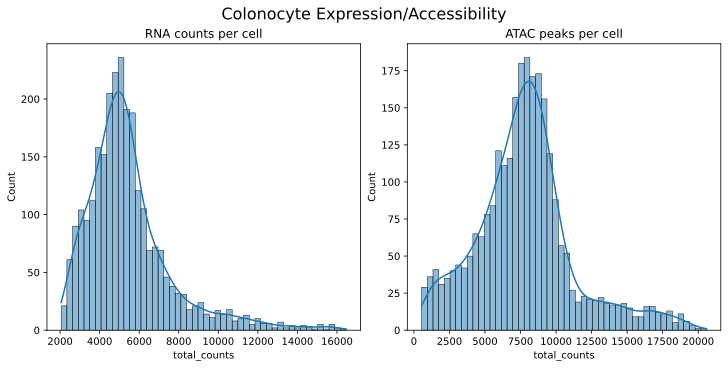

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib_inline import backend_inline

backend_inline.set_matplotlib_formats('svg')

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 5), layout="constrained")

sns.histplot(rna.obs["total_counts"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("RNA counts per cell")

sns.histplot(atac.obs["total_counts"], bins=50, kde=True, ax=ax[1])
ax[1].set_title("ATAC peaks per cell")

plt.suptitle(f"{selected_cell_type} Expression/Accessibility", fontsize=16)

plt.show()

### TF-Expression KDE Plot

In [4]:
# Load the TF names for the species from the motif information file
tf_name_file = PROJECT_DIR / "data" / "databases" / "motif_information" / "hg38" / "TF_Information_all_motifs.txt"
tf_name_df = pd.read_csv(tf_name_file, sep="\t")
tf_names = tf_name_df["TF_Name"].unique()
rna.var["tf"] = rna.var_names.isin(tf_names)
tf_rna = rna.var[rna.var["tf"] == True]
tf_rna

,gene_id,gene_ids,mt,ribo,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm,tf
HES4,ENSG00000188290.10,ENSG00000188290.10,False,False,476,0.041297,0.040467,96.325743,535.0,6.284134,374,False,0.081466,0.858611,-0.261676,True
SKI,ENSG00000157933.9,ENSG00000157933.9,False,False,1345,0.120340,0.113632,89.617908,1559.0,7.352441,1135,False,0.253642,1.011115,0.204137,True
HES5,ENSG00000197921.5,ENSG00000197921.5,False,False,15,0.001158,0.001157,99.884215,15.0,2.772589,11,False,0.002628,0.845160,-0.302760,True
PRDM16,ENSG00000142611.16,ENSG00000142611.16,False,False,268,0.025704,0.025380,97.931301,333.0,5.811141,241,True,0.066247,1.180871,0.722646,True
TP73,ENSG00000078900.14,ENSG00000078900.14,False,False,25,0.002161,0.002159,99.807024,28.0,3.367296,21,False,0.005671,0.947121,0.008673,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZNF280C,ENSG00000056277.15,ENSG00000056277.15,False,False,579,0.051872,0.050571,95.530683,672.0,6.511745,511,False,0.115490,1.010618,0.202619,True
ZNF75D,ENSG00000186376.14,ENSG00000186376.14,False,False,2502,0.278657,0.245810,80.686993,3610.0,8.191740,2150,False,0.503159,1.071800,-0.065775,True
ZNF449,ENSG00000173275.12,ENSG00000173275.12,False,False,473,0.038595,0.037869,96.348900,500.0,6.216606,394,False,0.087733,0.811621,-0.405204,True
ZNF275,ENSG00000063587.14,ENSG00000063587.14,False,False,273,0.021536,0.021307,97.892706,279.0,5.634789,225,False,0.048880,0.810998,-0.407106,True


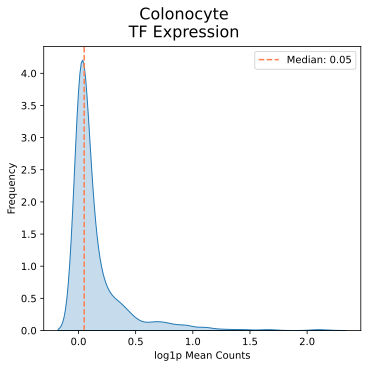

In [5]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 5), layout="constrained")

median_counts = tf_rna["log1p_mean_counts"].median()

sns.kdeplot(tf_rna["log1p_mean_counts"], fill=True)
ax.axvline(median_counts, color="coral", linestyle="--", label=f"Median: {median_counts:.2f}")
ax.legend()
ax.set_ylabel("Frequency")
ax.set_xlabel("log1p Mean Counts")

plt.suptitle(f"{selected_cell_type}\nTF Expression", fontsize=16)

plt.show()

### Peak Fragment Histogram

['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20']
{'fragments': '/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/ENCODE_colon/colon_adult_ENCDO856ZOJ/fragments_atac_barcodes.tsv.gz'}
/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/RAW_DATA/HUMAN/ENCODE_colon/colon_adult_ENCDO856ZOJ/fragments_atac_barcodes.tsv.gz
chr1:1-2000001 chr1	10001	10043	GGCAGGTTGACTAAGG	1


Fetching Regions...: 100%|██████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.04s/it]


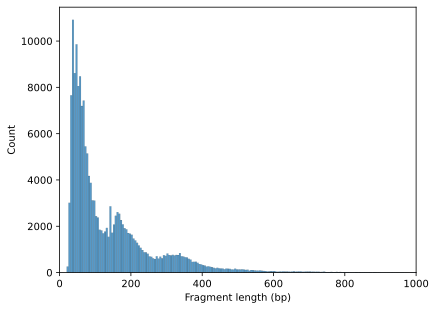

In [6]:
from muon import atac as ac
import pysam

index_file = str(frag_path) + ".tbi"

# Create the index file for the fragments
tbx = pysam.TabixFile(str(frag_path))
print(tbx.contigs[:20])

# register the fragment file with the ATAC AnnData
ac.tl.locate_fragments(atac, fragments=str(frag_path))

print(atac.uns["files"])
print(atac.uns["files"]["fragments"])
# optional grouping column if you want one
atac.obs["NS"] = 1

def find_nonempty_region(tbx, chrom="chr1", window=2_000_000, max_end=200_000_000):
    for start in range(1, max_end, window):
        rows = list(tbx.fetch(chrom, start, start + window))
        if rows:
            return f"{chrom}:{start}-{start+window}", rows[0]
    return None, None

region, example = find_nonempty_region(tbx, chrom="chr1")
print(region, example)

ac.pl.fragment_histogram(atac, region=region)


### Fragment TSS Enrichment

,Chromosome,Start,End
0,chr1,3069167,3069168
1,chr1,5307393,5307394
2,chr1,2413796,2413797


Fetching Regions...: 100%|██████████████████████████████████████████████████████████████████| 998/998 [00:29<00:00, 34.20it/s]
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


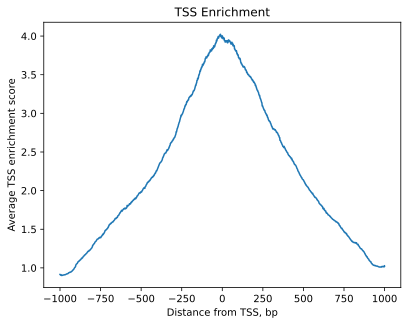

In [7]:
# Replace with your reference annotation; .gtf.gz also works.
gtf_path = "/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/data/genome_data/genome_annotation/hg38/Homo_sapiens.GRCh38.113.gtf.gz"

gtf = pd.read_csv(
    gtf_path,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "Chromosome", "Source", "Feature", "Start", "End",
        "Score", "Strand", "Frame", "Attributes",
    ],
    dtype={"Chromosome": str},
)

genes = gtf.loc[gtf["Feature"].eq("gene")].copy()

# Get strand-specific TSS positions and convert from 1-based to 0-based.
tss_position = np.where(
    genes["Strand"].eq("+"),
    genes["Start"] - 1,
    genes["End"] - 1,
).astype(int)

features = pd.DataFrame({
    "Chromosome": genes["Chromosome"].astype(str).to_numpy(),
    "Start": tss_position,
    "End": tss_position + 1,
}).drop_duplicates()

# If your fragments use chr1, chr2, ..., chrX, chrY, chrM,
# convert Ensembl's primary chromosome names to match:
chrom_map = {
    str(c): f"chr{c}"
    for c in [*range(1, 23), "X", "Y"]
}
chrom_map["MT"] = "chrM"

# Remove this line if your fragments use Ensembl names (1, 2, ..., MT).
features["Chromosome"] = features["Chromosome"].replace(chrom_map)

display(features.head(3))

ac.tl.locate_fragments(mdata, fragments=str(frag_path))

tss = ac.tl.tss_enrichment(
    mdata,
    features=features,
    n_tss=1000,
    random_state=0,
)

ac.pl.tss_enrichment(tss)

### Peaks per TF